# 05.1 · Ensembles: why many weak models beat one strong one

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/05-powerful-models/01-ensembles/lesson.ipynb)

Read the [README](README.md) first and do the five-voter table on paper. This notebook:

1. Computes the majority-vote formula and checks it by simulation.
2. Shows what happens when voters are **not** independent.
3. Builds a soft-voting ensemble of the three Module 03 churn models and compares it honestly.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

## 1. The majority-vote formula

In [2]:
from math import comb

def majority(n, p):
    """Probability that more than half of n independent voters (each right with prob p) are right."""
    return sum(comb(n, k) * p**k * (1 - p)**(n - k) for k in range(n // 2 + 1, n + 1))

# the by-hand table: 5 voters, each 60% right
for k in [3, 4, 5]:
    print(f"k={k}: C(5,{k})={comb(5, k):>2} × 0.6^{k} × 0.4^{5-k} = {comb(5, k) * 0.6**k * 0.4**(5-k):.5f}")
print(f"sum = {majority(5, 0.6):.4f}")

k=3: C(5,3)=10 × 0.6^3 × 0.4^2 = 0.34560
k=4: C(5,4)= 5 × 0.6^4 × 0.4^1 = 0.25920
k=5: C(5,5)= 1 × 0.6^5 × 0.4^0 = 0.07776
sum = 0.6826


In [3]:
for n in [1, 5, 25, 101]:
    print(f"{n:>3} voters → majority right {majority(n, 0.6):.1%}")

  1 voters → majority right 60.0%
  5 voters → majority right 68.3%
 25 voters → majority right 84.6%
101 voters → majority right 97.9%


### Check by simulation

Formulas can be wrong; simulations rarely lie. 10,000 rounds, 25 voters per round, each voter independently right with probability 0.6.

In [4]:
rng = np.random.default_rng(0)
votes = rng.random((10_000, 25)) < 0.6          # True = this voter is right
majority_right = votes.sum(axis=1) > 12          # more than 12 of 25 right
print(f"simulated: {majority_right.mean():.1%}   formula: {majority(25, 0.6):.1%}")

simulated: 84.9%   formula: 84.6%


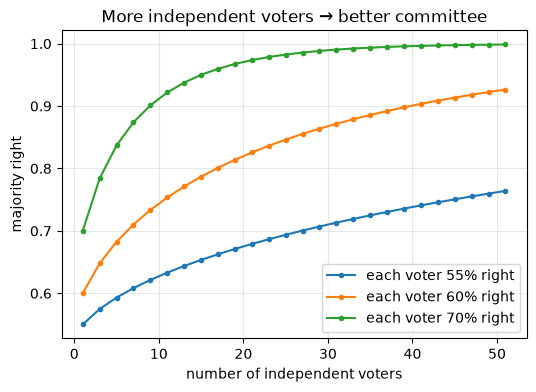

In [5]:
ns = range(1, 52, 2)
plt.figure(figsize=(6, 4))
for p in [0.55, 0.6, 0.7]:
    plt.plot(list(ns), [majority(n, p) for n in ns], marker=".", label=f"each voter {p:.0%} right")
plt.xlabel("number of independent voters"); plt.ylabel("majority right")
plt.title("More independent voters → better committee"); plt.legend(); plt.grid(alpha=.3); plt.show()

## 2. The catch: correlated voters

Now each voter, with probability 0.8, just copies a shared "mood" for that round (right 60% of the time), and otherwise thinks independently. This is what models trained on the same data are like: they share blind spots.

In [6]:
def correlated_rounds(n_voters, copy_prob, rounds=10_000, p=0.6, seed=0):
    rng = np.random.default_rng(seed)
    mood = rng.random((rounds, 1)) < p                     # shared answer per round
    own = rng.random((rounds, n_voters)) < p               # independent answers
    copies = rng.random((rounds, n_voters)) < copy_prob
    votes = np.where(copies, mood, own)
    return (votes.sum(axis=1) > n_voters // 2).mean()

for c in [0.0, 0.5, 0.8, 1.0]:
    print(f"copy probability {c:.1f}: 25-voter majority right {correlated_rounds(25, c):.1%}")

copy probability 0.0: 25-voter majority right 84.9%
copy probability 0.5: 25-voter majority right 61.0%
copy probability 0.8: 25-voter majority right 60.2%
copy probability 1.0: 25-voter majority right 60.2%


At copy probability 1.0 the 25 voters are clones, and the committee is no better than one voter (about 60%). Even at 0.5, half-copying, most of the gain is gone. **Diversity is the whole game.**

## 3. The churn table and the benchmark

In [7]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail
from sklearn.model_selection import train_test_split

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]
cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

def cv_auc(model):
    """Mean 5-fold cross-validated AUC on the training customers."""
    return cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc").mean()

def test_auc(model):
    """Fit on all training customers, score AUC on the held-out test customers."""
    model.fit(X_train, y_train)
    return roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])

print(f"Benchmark logistic regression: CV AUC {cv_auc(logreg):.3f}, test AUC {test_auc(logreg):.3f}")

Benchmark logistic regression: CV AUC 0.740, test AUC 0.741


## 4. Three different models

In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=51))
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
members = {"logistic regression": logreg, "KNN (k=51)": knn, "tree (depth 3)": tree}

for name, model in members.items():
    print(f"{name:<22} CV AUC {cv_auc(model):.3f}   test AUC {test_auc(model):.3f}")

logistic regression    CV AUC 0.740   test AUC 0.741
KNN (k=51)             CV AUC 0.732   test AUC 0.734


tree (depth 3)         CV AUC 0.731   test AUC 0.724


### Do they make different mistakes?

Voting can only help where the members disagree. Each model is now fitted on the training customers; we compare their yes/no predictions on the test customers.

In [10]:
preds = pd.DataFrame({name: m.predict(X_test) for name, m in members.items()})
all_agree = (preds.nunique(axis=1) == 1).mean()
print(f"all three agree on {all_agree:.0%} of test customers")
print(f"they disagree on {1 - all_agree:.0%}, which is where voting can change the answer")

all three agree on 82% of test customers
they disagree on 18%, which is where voting can change the answer


## 5. Soft voting

`voting="soft"` averages the three predicted probabilities. Each member keeps its own preprocessing inside its pipeline.

In [11]:
from sklearn.ensemble import VotingClassifier

vote = VotingClassifier(estimators=list(zip(["lr", "knn", "tree"], members.values())), voting="soft")
print(f"soft vote               CV AUC {cv_auc(vote):.3f}   test AUC {test_auc(vote):.3f}")

soft vote               CV AUC 0.744   test AUC 0.741


The vote edges the best single model in cross-validation and ties it on the test customers. That is the realistic outcome when the members are all decent and agree most of the time: **at least as good as the best member, more stable, not a miracle.**

The next two lessons build ensembles that are diverse *by design*: random forests (05.2) and boosting (05.3).

## Quiz answers

1. Each person's error is partly random; too-high and too-low guesses cancel when you take the median, leaving the shared signal.
2. The members' mistakes must be (at least partly) **different**: independent, or diverse. Each member must also be better than chance.
3. Bagging trains models **in parallel** (independently); boosting trains them **in sequence**, each fixing the previous ones.
4. Soft voting averages **predicted probabilities**; hard voting counts **predicted classes**.
5. Models trained on the same data with similar features share blind spots, so their errors are correlated; the binomial formula assumes independence.

**Next:** [05.2 Bagging and Random Forest](../02-random-forest/)